# FoodLens — Phase 2: Exploratory Data Analysis

**University semester ETL project · saved Open Food Facts snapshots · exploratory analysis only**

This notebook investigates the completed Phase 1 combined export before any Phase 3
cleaning. The expected baseline (2,000 source records, 1,987 unique products, 24
columns and 13 overlapping products) is verified below against the CSV, metadata,
checkpoints and saved page responses. These are expectations to test, not assumed findings.

Questions:
1. How complete are the identity, nutrient, classification and provenance fields?
2. Are barcodes unique, and are all extraction-category memberships preserved?
3. How do nutrient distributions and classifications differ within this sample?
4. Which values violate basic representations, warrant source review, or are merely unusual?
5. What evidence should inform later cleaning decisions?

**Reproduction:** select the project's `.venv` Python kernel and run all cells in
order. The working directory may be the repository root or `notebooks/`.
Install optional tools with `python -m pip install -r requirements-eda.txt`.
From the root, `python scripts/execute_eda.py` executes this notebook from both
locations and saves outputs only after both runs pass. No API requests are made.

**Preservation:** source files are read only. Numeric coercion, membership
explosion, missing-label display and finite-value filtering are temporary EDA
views. No cleaned dataset, imputation, deduplication or outlier removal is saved.

## 1. Setup and portable file resolution

Barcodes are read as strings, preserving leading zeroes. Only empty CSV fields are
treated as missing at import, so literal text such as `NA` is not silently discarded.
Whitespace-only fields are counted separately in the missingness investigation.

In [1]:
from pathlib import Path
from collections import defaultdict
import hashlib
import json
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.labelsize": 11})
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_colwidth", 48)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

DATA_RELATIVE = Path("data/processed/food_products_analysis_combined_725f8a023f0f8ee6.csv")
candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((path for path in candidates if (path / DATA_RELATIVE).is_file()
             and (path / "src/download_dataset.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks directory with the Phase 1 data present.")
csv_path = ROOT / DATA_RELATIVE
metadata = json.loads(csv_path.with_suffix(".json").read_text(encoding="utf-8"))
csv_hash_before = hashlib.sha256(csv_path.read_bytes()).hexdigest()
df = pd.read_csv(csv_path, dtype={"barcode": "string"}, keep_default_na=False, na_values=[""])
original_frame = df.copy(deep=True)  # Used only to prove the source DataFrame is not changed.

CATEGORIES = ["breakfast-cereals", "yogurts", "biscuits", "cereal-bars"]
LABELS = dict(zip(CATEGORIES, ["Breakfast cereals", "Yogurts", "Biscuits", "Cereal bars"]))
COLORS = dict(zip(CATEGORIES, ["#27647b", "#db9b34", "#9a5676", "#568568"]))
NUTRIENTS = {
    "energy_kcal_100g": "Energy (kcal/100 g)",
    "energy_kj_100g": "Energy (kJ/100 g)",
    "protein_g_100g": "Protein (g/100 g)",
    "carbohydrates_g_100g": "Carbohydrates (g/100 g)",
    "sugars_g_100g": "Sugars (g/100 g)",
    "fat_g_100g": "Fat (g/100 g)",
    "saturated_fat_g_100g": "Saturated fat (g/100 g)",
    "fiber_g_100g": "Fiber (g/100 g)",
    "salt_g_100g": "Salt (g/100 g)",
}
print("Input:", DATA_RELATIVE.as_posix())
print("Python:", platform.python_version())
display(pd.Series({name: version(name) for name in ["pandas", "numpy", "matplotlib", "nbclient"]}, name="version").to_frame())

Input: data/processed/food_products_analysis_combined_725f8a023f0f8ee6.csv
Python: 3.12.4


,version
pandas,3.0.6
numpy,2.5.3
matplotlib,3.11.2
nbclient,0.11.0


## 2. Verify Phase 1 provenance and sample structure

The combined metadata's content hash must match the CSV. Each category checkpoint
and each page's response checksum are checked independently, without importing or
running the downloader. Only selected non-sensitive metadata are displayed.
The 100 legacy records lack their original extraction timestamp; their import
timestamp must not be mistaken for an extraction time.

In [2]:
assert csv_hash_before == metadata["output_csv_sha256"], "Combined CSV checksum mismatch"
assert list(df.columns) == metadata["analysis_columns"], "Combined schema mismatch"
assert metadata["categories"] == CATEGORIES
assert set(NUTRIENTS).issubset(df.columns)

raw_memberships = defaultdict(set)
raw_lookup = {}
raw_rows = []
source_summary = []
for category in CATEGORIES:
    ids = df.loc[df["extraction_category"].eq(category), "extraction_id"].unique()
    assert len(ids) == 1
    extraction_id = ids[0]
    extraction_dir = ROOT / "data/raw/extractions" / extraction_id
    checkpoint = json.loads((extraction_dir / "checkpoint.json").read_text(encoding="utf-8"))
    assert checkpoint["status"] == "complete"
    assert checkpoint["configuration"]["query_parameters"]["categories_tags_en"] == category
    per_category_csv = ROOT / "data/processed" / f"food_products_analysis_{extraction_id}.csv"
    assert hashlib.sha256(per_category_csv.read_bytes()).hexdigest() == checkpoint["analysis_csv_sha256"]
    page_paths = sorted((extraction_dir / "pages").glob("page_*.json"))
    pages_seen, codes = [], []
    for path in page_paths:
        envelope = json.loads(path.read_text(encoding="utf-8"))
        payload = envelope["response"]
        canonical = (json.dumps(payload, ensure_ascii=False, sort_keys=True, indent=2, allow_nan=False) + "\n").encode("utf-8")
        response_hash = hashlib.sha256(canonical).hexdigest()
        assert response_hash == envelope["response_sha256"]
        assert response_hash == checkpoint["page_response_sha256"][str(envelope["page"]) ]
        assert envelope["configuration"] == checkpoint["configuration"]
        assert envelope["row_count"] == len(payload["products"])
        pages_seen.append(envelope["page"])
        for record_index, product in enumerate(payload["products"]):
            barcode = product.get("code")
            codes.append(barcode)
            raw_memberships[barcode].add(category)
            raw_lookup[(extraction_id, envelope["page"], record_index)] = product
            raw_rows.append({"category": category, "product": product})
    assert pages_seen == checkpoint["completed_pages"]
    assert len(codes) == checkpoint["row_counts"]["raw_records"] == metadata["category_counts"][category]["raw_records"]
    assert len(set(codes)) == checkpoint["row_counts"]["unique_products"]
    source_summary.append({"category": LABELS[category], "saved_pages": len(pages_seen),
                           "source_records": len(codes), "unique_barcodes": len(set(codes)),
                           "checkpoint": checkpoint["status"], "checksums": "verified"})

source_summary = pd.DataFrame(source_summary)
baseline = pd.DataFrame({
    "measure": ["Source records", "Unique products", "Analytical columns", "Extraction categories", "Overlapping products"],
    "expected": [2000, 1987, 24, 4, 13],
    "observed": [len(raw_rows), df["barcode"].nunique(), len(df.columns),
                 len(source_summary), sum(len(values) > 1 for values in raw_memberships.values())],
})
assert baseline["expected"].equals(baseline["observed"]), "Phase 1 baseline changed; investigate before interpreting"
assert metadata["raw_records"] == len(raw_rows)
assert metadata["unique_products"] == len(df) == len(raw_memberships)
display(baseline, source_summary)
print("CSV dimensions:", df.shape)
display(df.dtypes.astype(str).rename("dtype").to_frame())
display(df.head(5))

,measure,expected,observed
0,Source records,2000,2000
1,Unique products,1987,1987
2,Analytical columns,24,24
3,Extraction categories,4,4
4,Overlapping products,13,13


,category,saved_pages,source_records,unique_barcodes,checkpoint,checksums
0,Breakfast cereals,5,500,500,complete,verified
1,Yogurts,5,500,500,complete,verified
2,Biscuits,5,500,500,complete,verified
3,Cereal bars,5,500,500,complete,verified


CSV dimensions: (1987, 24)


,dtype
barcode,string
product_name,str
brands,str
categories,str
energy_kcal_100g,float64
energy_kj_100g,float64
protein_g_100g,float64
carbohydrates_g_100g,float64
sugars_g_100g,float64
fat_g_100g,float64


,barcode,product_name,brands,categories,energy_kcal_100g,energy_kj_100g,protein_g_100g,carbohydrates_g_100g,sugars_g_100g,fat_g_100g,saturated_fat_g_100g,fiber_g_100g,salt_g_100g,nutriscore_grade,nova_group,source_page,source_record_index,extracted_at_utc,source_url,record_origin,extraction_id,extraction_category,extraction_categories,category_membership_count
0,3168930010265,cruesly mélange de noix,PEPSICO FRANCE,en:plant-based-foods-and-beverages;en:plant-...,462.000,"1,913.000",8.500,57.000,12.000,19.000,2.000,10.000,0.000,b,4.000,1,0,NaN,https://world.openfoodfacts.org/api/v2/searc...,legacy_import,255549a7a8a480c0,breakfast-cereals,breakfast-cereals,1
1,3229820160672,Croustillant Chocolat,Bjorg,en:plant-based-foods-and-beverages;en:plant-...,431.667,"1,817.000",9.270,62.000,14.000,14.000,3.400,10.000,0.260,c,4.000,1,1,NaN,https://world.openfoodfacts.org/api/v2/searc...,legacy_import,255549a7a8a480c0,breakfast-cereals,breakfast-cereals,1
2,3229820019307,Flocons d'avoine,BJORG ET CIE,en:plant-based-foods-and-beverages;en:plant-...,363.333,"1,524.000",11.000,58.000,1.700,7.100,1.300,11.000,0.020,a,1.000,1,2,NaN,https://world.openfoodfacts.org/api/v2/searc...,legacy_import,255549a7a8a480c0,breakfast-cereals,breakfast-cereals,1
3,3229820129488,"Muesli Raisin, Figue, Datte, Abricot","Bjorg, BJORG ET CIE",en:plant-based-foods-and-beverages;en:plant-...,352.000,"1,485.000",11.000,59.000,14.000,5.800,0.900,10.000,0.030,a,3.000,1,3,NaN,https://world.openfoodfacts.org/api/v2/searc...,legacy_import,255549a7a8a480c0,breakfast-cereals,breakfast-cereals,1
4,3387390123210,Chocapic,"Nestlé, Chocapic",en:plant-based-foods-and-beverages;en:plant-...,384.000,"1,624.000",8.500,73.800,19.900,4.400,1.100,7.700,0.200,b,4.000,1,4,NaN,https://world.openfoodfacts.org/api/v2/searc...,legacy_import,255549a7a8a480c0,breakfast-cereals,breakfast-cereals,1


## 3. Completeness, missingness and provenance

Percentages below always use all unique product rows as the denominator.
The table covers **all 24 columns**. Missing nutrition is not automatically an
error and is not replaced by zero. Phase 1 already exported missing, negative
and non-finite nutrient inputs as blanks, so a clean-looking CSV is not proof
that its underlying source was complete or valid.

In [3]:
whitespace_only = df.astype("string").apply(lambda column: column.str.fullmatch(r"\s*", na=False))
missing_mask = df.isna() | whitespace_only
missing = pd.DataFrame({
    "missing_count": missing_mask.sum(),
    "missing_pct": missing_mask.mean().mul(100),
    "whitespace_only_count": whitespace_only.sum(),
    "present_count": (~missing_mask).sum(),
}).sort_values(["missing_count"], ascending=False)
display(missing)
provenance = df.groupby("record_origin", dropna=False).agg(
    products=("barcode", "size"), recorded_extraction_times=("extracted_at_utc", "count"))
provenance["missing_extraction_times"] = provenance["products"] - provenance["recorded_extraction_times"]
display(provenance)

,missing_count,missing_pct,whitespace_only_count,present_count
fiber_g_100g,351,17.665,0,1636
nova_group,130,6.543,0,1857
nutriscore_grade,116,5.838,0,1871
extracted_at_utc,100,5.033,0,1887
salt_g_100g,66,3.322,0,1921
energy_kj_100g,55,2.768,0,1932
saturated_fat_g_100g,54,2.718,0,1933
sugars_g_100g,50,2.516,0,1937
carbohydrates_g_100g,44,2.214,0,1943
protein_g_100g,43,2.164,0,1944


,products,recorded_extraction_times,missing_extraction_times
record_origin,,,
api,1887,1887,0
legacy_import,100,0,100


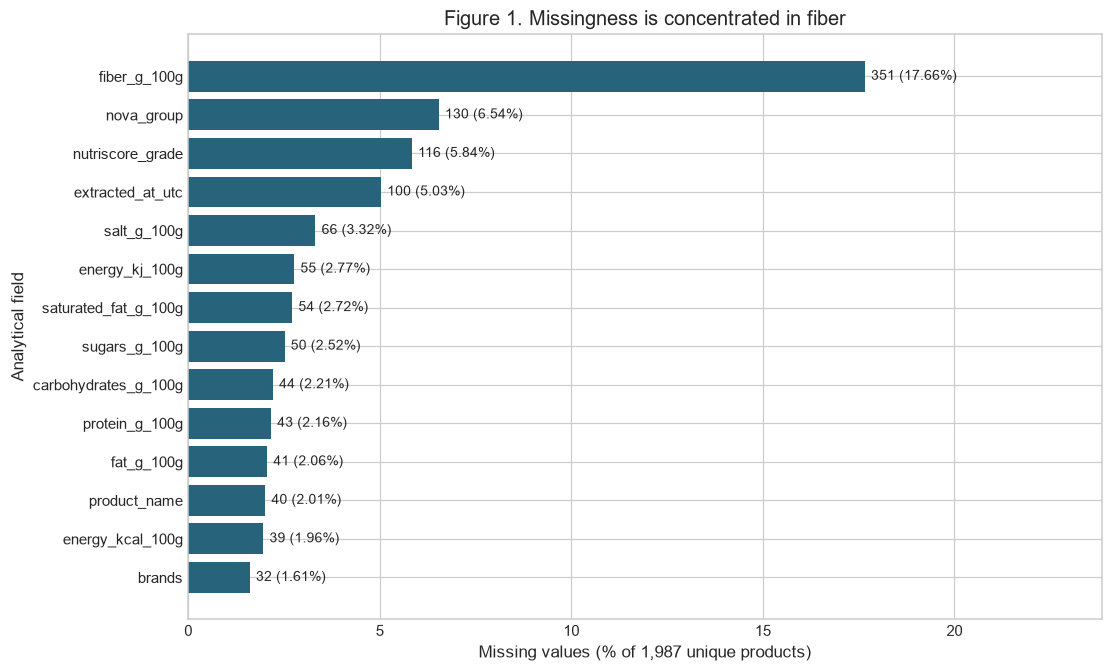

**Interpretation.** `fiber_g_100g` has 351 missing values (17.66%). Nutri-Score is missing for 116 products and NOVA for 130. All 100 missing extraction timestamps belong to legacy imports. Their original times cannot be recovered from this export.

In [4]:
# Figure 1: only fields with observed missingness; the full table above includes zeros.
to_plot = missing.loc[missing["missing_count"].gt(0)].sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
bars = ax.barh(to_plot.index, to_plot["missing_pct"], color="#27647b")
ax.bar_label(bars, labels=[f"{count} ({pct:.2f}%)" for count, pct in zip(to_plot["missing_count"], to_plot["missing_pct"])], padding=4, fontsize=9)
ax.set(xlabel=f"Missing values (% of {len(df):,} unique products)", ylabel="Analytical field",
       title="Figure 1. Missingness is concentrated in fiber", xlim=(0, to_plot["missing_pct"].max() * 1.35))
plt.show()
plt.close(fig)
top_missing = missing.index[0]
display(Markdown(
    f"**Interpretation.** `{top_missing}` has {int(missing.loc[top_missing, 'missing_count']):,} missing values "
    f"({missing.loc[top_missing, 'missing_pct']:.2f}%). Nutri-Score is missing for "
    f"{int(missing.loc['nutriscore_grade', 'missing_count'])} products and NOVA for "
    f"{int(missing.loc['nova_group', 'missing_count'])}. "
    f"All {int(provenance.loc['legacy_import', 'missing_extraction_times'])} missing extraction timestamps "
    "belong to legacy imports. Their original times cannot be recovered from this export."
))

## 4. Identity, category membership and overlap

`categories` contains source taxonomy tags. `extraction_category` identifies the
first extraction whose row was retained during combination; it is **not an
exclusive product classification**. `extraction_categories` preserves every
selected extraction membership.

**Comparison policy:** all category comparisons use an in-memory exploded view
of `extraction_categories`. A product appears once in each of its categories,
but only once in overall summaries. Thus groups may overlap and are not independent.
The retained product/nutrient values still come from the first extracted row;
exploding memberships does not retrieve later category-specific versions.

In [5]:
memberships = df["extraction_categories"].str.split(";")
membership_ok = memberships.map(lambda values: isinstance(values, list) and len(values) == len(set(values))
                                and set(values).issubset(CATEGORIES))
counts_ok = memberships.str.len().eq(df["category_membership_count"])
primary_ok = pd.Series([primary in values for primary, values in zip(df["extraction_category"], memberships)], index=df.index)
raw_match = pd.Series([set(values) == raw_memberships[barcode] for barcode, values in zip(df["barcode"], memberships)], index=df.index)
identifier_checks = pd.Series({
    "missing_barcodes": int(missing_mask["barcode"].sum()),
    "duplicate_barcode_rows_after_first": int(df["barcode"].duplicated().sum()),
    "invalid_barcode_format": int((~df["barcode"].str.fullmatch(r"[0-9]{8,14}", na=False)).sum()),
    "leading_zero_barcodes": int(df["barcode"].str.startswith("0", na=False).sum()),
    "invalid_membership_lists": int((~membership_ok).sum()),
    "membership_count_mismatches": int((~counts_ok).sum()),
    "primary_category_not_in_memberships": int((~primary_ok).sum()),
    "memberships_differ_from_saved_pages": int((~raw_match).sum()),
}, name="count")
display(identifier_checks.to_frame())
assert membership_ok.all() and counts_ok.all() and primary_ok.all() and raw_match.all()
assert not df["barcode"].duplicated().any() and df["barcode"].notna().all()
membership_view = df.assign(membership=memberships).explode("membership", ignore_index=True)
primary_counts = df["extraction_category"].value_counts().reindex(CATEGORIES, fill_value=0)
all_counts = membership_view["membership"].value_counts().reindex(CATEGORIES, fill_value=0)
assert all_counts.to_dict() == metadata["unique_products_by_category"]
assert len(membership_view) == len(raw_rows)
overlap = df.loc[df["category_membership_count"].gt(1), ["barcode", "product_name", "extraction_categories"]]
overlap_pairs = overlap["extraction_categories"].value_counts().rename("products")
display(overlap_pairs.to_frame(), overlap)
display(df["categories"].str.split(";").explode().value_counts().head(12).rename("products_with_taxonomy_tag").to_frame())

,count
missing_barcodes,0
duplicate_barcode_rows_after_first,0
invalid_barcode_format,0
leading_zero_barcodes,83
invalid_membership_lists,0
membership_count_mismatches,0
primary_category_not_in_memberships,0
memberships_differ_from_saved_pages,0


,products
extraction_categories,
breakfast-cereals;cereal-bars,7
breakfast-cereals;biscuits,2
breakfast-cereals;yogurts,2
biscuits;cereal-bars,2


,barcode,product_name,extraction_categories
150,5010029000504,Whole wheat cereal with added vitamins and i...,breakfast-cereals;biscuits
253,0016000264694,Oats 'N Honey Granola Bars,breakfast-cereals;cereal-bars
275,6111250010948,NaN,breakfast-cereals;yogurts
305,5900617015945,Crunchy Nut & Almond,breakfast-cereals;cereal-bars
311,6111032007685,Yaourt cereal,breakfast-cereals;yogurts
340,8410376042894,gullon heart of cereals,breakfast-cereals;biscuits
381,3159470204412,Special K Chocolat Noir Pure Chocolate,breakfast-cereals;cereal-bars
386,3596710494132,Muesli croustillant quinoa chocolat,breakfast-cereals;cereal-bars
411,5060088700822,TREK PROTEIN AVOINE - Biscoff (3x1p),breakfast-cereals;cereal-bars
435,4056489627159,Barres de céréales chocolat noir,breakfast-cereals;cereal-bars


,products_with_taxonomy_tag
categories,
en:snacks,1005
en:sweet-snacks,1004
en:plant-based-foods-and-beverages,599
en:plant-based-foods,590
en:breakfasts,558
en:cereals-and-potatoes,557
en:cereals-and-their-products,555
en:breakfast-cereals,534
en:biscuits-and-cakes,523


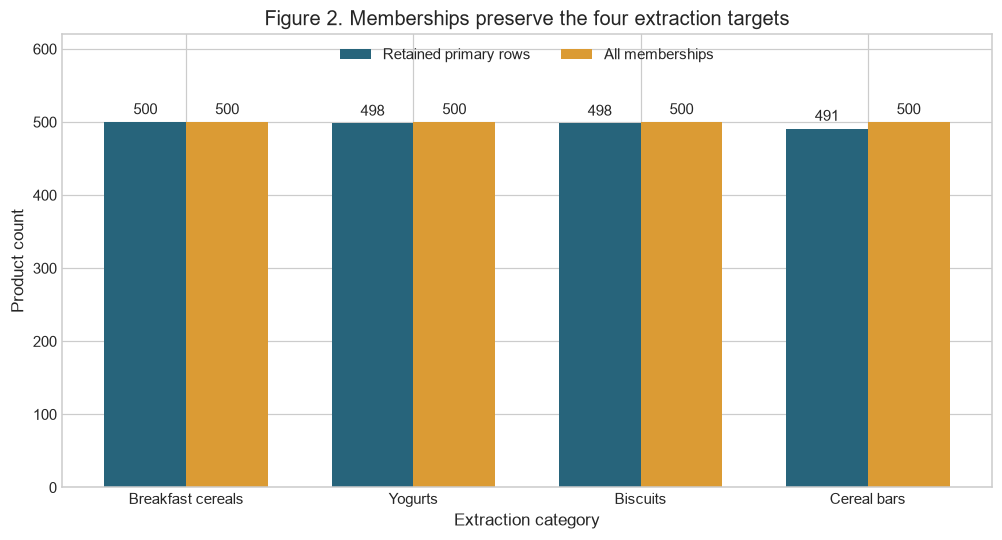

**Interpretation.** Each category contains 500 memberships. Primary retained-row counts are Breakfast cereals: 500, Yogurts: 498, Biscuits: 498, Cereal bars: 491. The 2,000 memberships correspond to 1,987 unique products; 13 products have two memberships. Equal category counts reflect extraction targets, not equal category sizes in Open Food Facts or the food market.

In [6]:
# Figure 2: counts describe the sampling/combination design, not market prevalence.
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
x = np.arange(len(CATEGORIES))
first = ax.bar(x - .18, primary_counts, .36, label="Retained primary rows", color="#27647b")
all_members = ax.bar(x + .18, all_counts, .36, label="All memberships", color="#db9b34")
ax.bar_label(first, padding=3)
ax.bar_label(all_members, padding=3)
ax.set(xticks=x, xticklabels=[LABELS[c] for c in CATEGORIES], ylabel="Product count", xlabel="Extraction category",
       title="Figure 2. Memberships preserve the four extraction targets", ylim=(0, 620))
ax.legend(loc="upper center", ncols=2)
plt.show()
plt.close(fig)
display(Markdown(
    f"**Interpretation.** Each category contains {int(all_counts.min())} memberships. "
    f"Primary retained-row counts are {', '.join(f'{LABELS[c]}: {primary_counts[c]}' for c in CATEGORIES)}. "
    f"The {len(membership_view):,} memberships correspond to {len(df):,} unique products; "
    f"{len(overlap)} products have two memberships. Equal category counts reflect extraction targets, "
    "not equal category sizes in Open Food Facts or the food market."
))

## 5. Product names and brand strings

Names are descriptive text, not keys. Repeated names across distinct barcodes do
not establish duplicate products. Brand counts below use **exact stored brand
strings**, which may combine several brands or contain spelling/case variants.
No brand splitting or standardization is performed.

In [7]:
text_rows = []
for column in ["product_name", "brands"]:
    values = df[column].dropna()
    text_rows.append({"field": column, "present": len(values), "unique_exact_strings": values.nunique(),
                      "rows_with_repeated_string": int(values.duplicated(keep=False).sum()),
                      "edge_whitespace_rows": int(values.ne(values.str.strip()).sum()),
                      "distinct_after_casefold_and_trim_preview": values.str.strip().str.casefold().nunique()})
display(pd.DataFrame(text_rows).set_index("field"))
display(df["product_name"].value_counts().head(10).rename("barcodes_with_this_exact_name").to_frame())
top_brands = df["brands"].value_counts().head(10)
display(top_brands.rename("products").to_frame())

,present,unique_exact_strings,rows_with_repeated_string,edge_whitespace_rows,distinct_after_casefold_and_trim_preview
field,,,,,
product_name,1947,1857,154,0,1802
brands,1955,688,1503,0,604


,barcodes_with_this_exact_name
product_name,
Flocons d'avoine,7
Yaourt nature,6
Weetabix,4
Corn Flakes,4
Yaourt à la grecque,4
Yaourt,4
Petit beurre,4
Original,3
CORN FLAKES,3


,products
brands,
MERCADONA,64
Gerblé,62
Bjorg,52
Danone,47
Nature Valley,44
Kellogg's,39
Crownfield,34
Nestlé,32
Jaouda,32


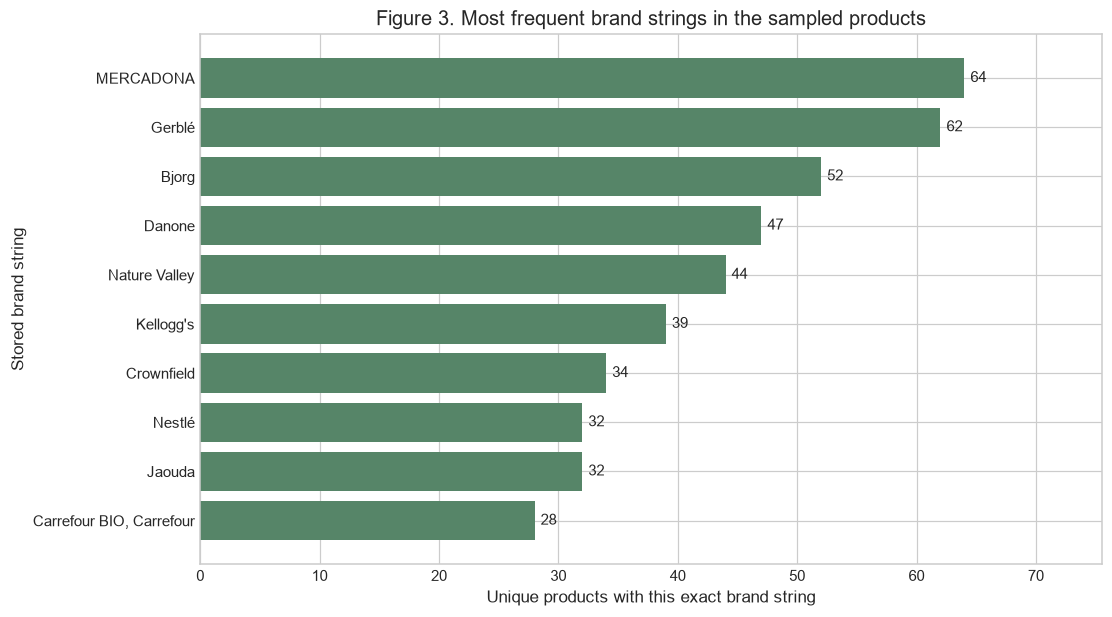

**Interpretation.** The most frequent exact brand string is **MERCADONA**, with 64 products (3.22% of this sample). Brand information is missing for 32 products; names are missing for 40. These counts describe this API sample and cannot be interpreted as market share.

In [8]:
# Figure 3: exact source brand labels, not inferred companies or market shares.
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
bars = ax.barh(top_brands.index[::-1], top_brands.values[::-1], color="#568568")
ax.bar_label(bars, padding=4)
ax.set(xlabel="Unique products with this exact brand string", ylabel="Stored brand string",
       title="Figure 3. Most frequent brand strings in the sampled products", xlim=(0, top_brands.max() * 1.18))
plt.show()
plt.close(fig)
display(Markdown(
    f"**Interpretation.** The most frequent exact brand string is **{top_brands.index[0]}**, "
    f"with {int(top_brands.iloc[0])} products ({top_brands.iloc[0] / len(df) * 100:.2f}% of this sample). "
    f"Brand information is missing for {int(missing.loc['brands', 'missing_count'])} products; "
    f"names are missing for {int(missing.loc['product_name', 'missing_count'])}. "
    "These counts describe this API sample and cannot be interpreted as market share."
))

## 6. Nutri-Score and NOVA coverage

Nutri-Score grades and NOVA groups are stored classifications, not results
recomputed here. Missing classifications remain a separate chart category and
stay in each denominator. We do not infer an absent grade from its nutrients,
or interpret a missing NOVA group as group 1. No NOVA group is silently dropped
from the display just because its observed count is zero.

In [9]:
grade_levels = ["a", "b", "c", "d", "e", "Missing"]
nova_levels = ["1", "2", "3", "4", "Missing"]
grade_values = df["nutriscore_grade"]
nova_numeric = pd.to_numeric(df["nova_group"], errors="coerce")
invalid_grade = grade_values.notna() & ~grade_values.isin(grade_levels[:-1])
invalid_nova = df["nova_group"].notna() & ~nova_numeric.isin([1, 2, 3, 4])
display(pd.Series({"unexpected_Nutri_Score_values": int(invalid_grade.sum()),
                   "unexpected_NOVA_values": int(invalid_nova.sum())}, name="count").to_frame())
assert not invalid_grade.any() and not invalid_nova.any(), "Review unexpected classifications before charting"
grade_counts = grade_values.fillna("Missing").value_counts().reindex(grade_levels, fill_value=0)
nova_labels = nova_numeric.map(lambda x: str(int(x)) if pd.notna(x) else "Missing")
nova_counts = nova_labels.value_counts().reindex(nova_levels, fill_value=0)
display(pd.DataFrame({"count": grade_counts, "percent_all_products": grade_counts / len(df) * 100}))
display(pd.DataFrame({"count": nova_counts, "percent_all_products": nova_counts / len(df) * 100}))
grade_by_category = pd.crosstab(membership_view["membership"], membership_view["nutriscore_grade"].fillna("Missing")).reindex(index=CATEGORIES, columns=grade_levels, fill_value=0)
nova_by_category = pd.crosstab(membership_view["membership"], membership_view["nova_group"].map(lambda x: str(int(x)) if pd.notna(x) else "Missing")).reindex(index=CATEGORIES, columns=nova_levels, fill_value=0)
assert grade_by_category.sum(axis=1).equals(all_counts.rename(None))
assert nova_by_category.sum(axis=1).equals(all_counts.rename(None))
display(grade_by_category.rename(index=LABELS), nova_by_category.rename(index=LABELS))

,count
unexpected_Nutri_Score_values,0
unexpected_NOVA_values,0


,count,percent_all_products
nutriscore_grade,,
a,287,14.444
b,183,9.210
c,602,30.297
d,410,20.634
e,389,19.577
Missing,116,5.838


,count,percent_all_products
nova_group,,
1,158,7.952
2,0,0.000
3,363,18.269
4,1336,67.237
Missing,130,6.543


nutriscore_grade,a,b,c,d,e,Missing
membership,,,,,,
Breakfast cereals,155,55,188,77,19,6
Yogurts,107,91,206,24,31,41
Biscuits,6,26,79,107,268,14
Cereal bars,20,11,130,211,73,55


nova_group,1,2,3,4,Missing
membership,,,,,
Breakfast cereals,58,0,164,262,16
Yogurts,100,0,87,234,79
Biscuits,0,0,71,413,16
Cereal bars,0,0,43,437,20


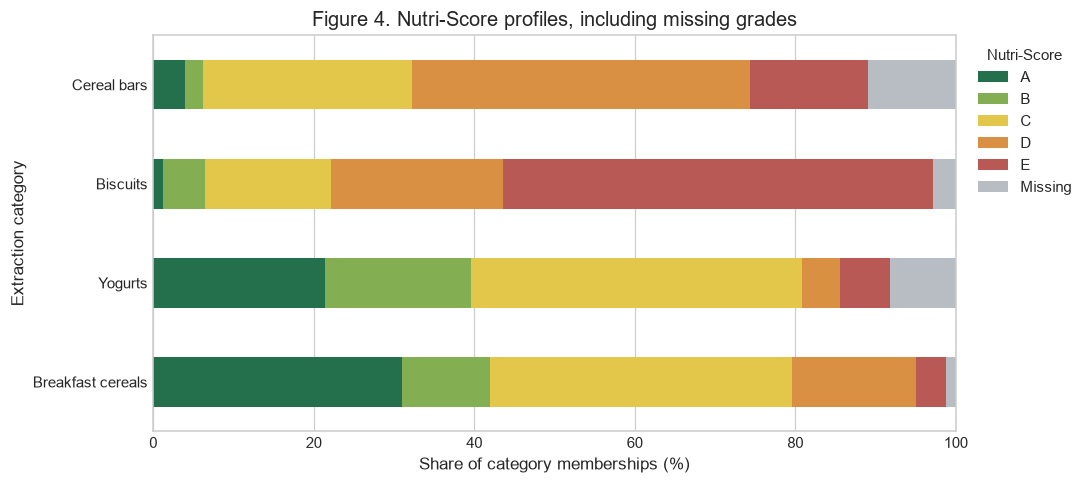

**Interpretation.** Grades D/E account for Breakfast cereals: 19.2%; Yogurts: 11.0%; Biscuits: 75.0%; Cereal bars: 56.8% of memberships, including missing grades in the denominator. Overall, grade C occurs 602 times, and 116 unique products lack a grade. These are descriptive sample differences, not causal or population estimates.

In [10]:
# Figure 4: all memberships; missing grades included in denominators.
grade_pct = grade_by_category.div(all_counts, axis=0).mul(100)
ax = grade_pct.rename(index=LABELS, columns={g: g.upper() for g in grade_levels[:-1]}).plot.barh(
    stacked=True, figsize=(10, 4.5), color=["#24704d", "#83ae52", "#e2c74b", "#d99043", "#b95955", "#b8bdc3"])
ax.set(xlabel="Share of category memberships (%)", ylabel="Extraction category",
       title="Figure 4. Nutri-Score profiles, including missing grades", xlim=(0, 100))
ax.legend(title="Nutri-Score", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.figure.tight_layout()
plt.show()
plt.close(ax.figure)
de_pct = grade_pct[["d", "e"]].sum(axis=1)
display(Markdown(
    "**Interpretation.** Grades D/E account for " + "; ".join(f"{LABELS[c]}: {de_pct[c]:.1f}%" for c in CATEGORIES)
    + f" of memberships, including missing grades in the denominator. Overall, grade C occurs "
    f"{int(grade_counts['c'])} times, and {int(grade_counts['Missing'])} unique products lack a grade. "
    "These are descriptive sample differences, not causal or population estimates."
))

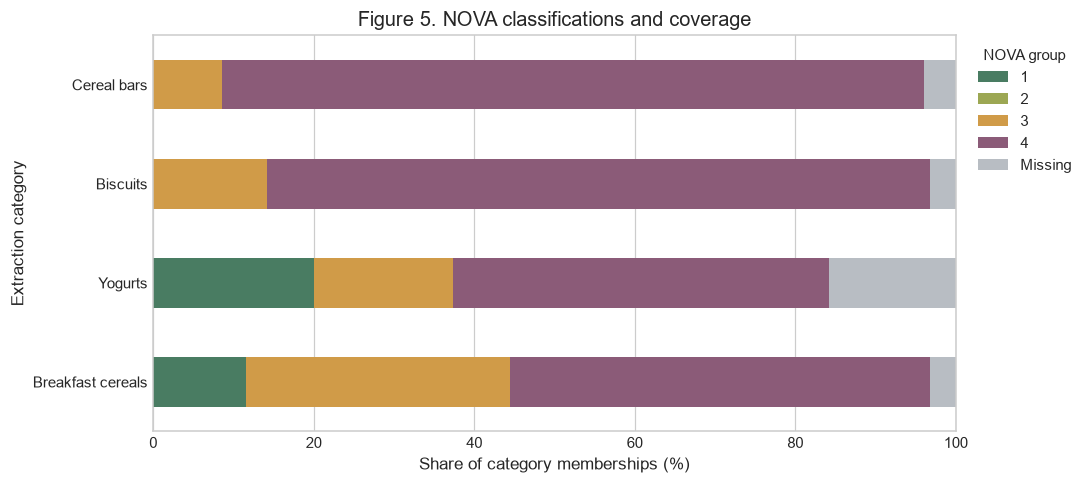

**Interpretation.** NOVA 4 appears in 1,336/1,987 unique products (67.24%), or 71.94% of the 1,857 classified products. 130 products lack NOVA. Group-4 shares by membership are Breakfast cereals: 52.4%; Yogurts: 46.8%; Biscuits: 82.6%; Cereal bars: 87.4%. Missingness prevents treating classified-only percentages as complete coverage.

In [11]:
# Figure 5: retain zero-count group 2 and unclassified products explicitly.
nova_pct = nova_by_category.div(all_counts, axis=0).mul(100)
ax = nova_pct.rename(index=LABELS).plot.barh(stacked=True, figsize=(10, 4.5),
    color=["#497c62", "#9ca753", "#d09b48", "#8b5b78", "#b8bdc3"])
ax.set(xlabel="Share of category memberships (%)", ylabel="Extraction category",
       title="Figure 5. NOVA classifications and coverage", xlim=(0, 100))
ax.legend(title="NOVA group", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.figure.tight_layout()
plt.show()
plt.close(ax.figure)
nova_known = int(nova_counts.drop("Missing").sum())
display(Markdown(
    f"**Interpretation.** NOVA 4 appears in {int(nova_counts['4']):,}/{len(df):,} unique products "
    f"({nova_counts['4'] / len(df) * 100:.2f}%), or {nova_counts['4'] / nova_known * 100:.2f}% of "
    f"the {nova_known:,} classified products. {int(nova_counts['Missing'])} products lack NOVA. "
    + "Group-4 shares by membership are " + "; ".join(f"{LABELS[c]}: {nova_pct.loc[c, '4']:.1f}%" for c in CATEGORIES)
    + ". Missingness prevents treating classified-only percentages as complete coverage."
))

## 7. Nutrient summaries and category distributions

All units below are the export's declared per-100-g basis. The export does not
include serving sizes, original unit fields or preparation basis (see Section 9).
`pd.to_numeric(errors='coerce')` is used **only in a separate numeric view**;
conversion failures are counted before calculations. Non-finite/missing values
are omitted per field for descriptive calculations, not removed from the dataset.
Finite suspicious values and outliers remain in all summaries and plots.

Tables show available-case counts, mean, spread, quartiles and extremes; unlike
the mean, a median is less sensitive to a few extreme values. None of these
summaries establish a recommended diet or a product's overall quality.

In [12]:
numeric = df[list(NUTRIENTS)].apply(pd.to_numeric, errors="coerce")
conversion_failures = df[list(NUTRIENTS)].notna() & numeric.isna()
nonfinite = numeric.notna() & ~np.isfinite(numeric)
negative = numeric.lt(0)
representation_checks = pd.DataFrame({"parse_failures": conversion_failures.sum(),
                                      "nonfinite_values": nonfinite.sum(),
                                      "negative_values": negative.sum(),
                                      "zero_values": numeric.eq(0).sum()})
display(representation_checks)
finite = numeric.where(np.isfinite(numeric))  # temporary, no imputation
descriptive = finite.describe(percentiles=[.01, .25, .5, .75, .99]).T
descriptive.insert(0, "label_and_unit", pd.Series(NUTRIENTS))
display(descriptive)
nutrient_memberships = finite.assign(membership=memberships).explode("membership", ignore_index=True)
category_descriptive = nutrient_memberships.groupby("membership")[list(NUTRIENTS)].agg(["count", "median", "mean", "min", "max"])
category_descriptive = category_descriptive.reindex(CATEGORIES)
category_medians = nutrient_memberships.groupby("membership")[list(NUTRIENTS)].median().reindex(CATEGORIES)
category_available = nutrient_memberships.groupby("membership")[list(NUTRIENTS)].count().reindex(CATEGORIES)
category_missing_pct = (1 - category_available.div(all_counts, axis=0)) * 100
display(category_medians.rename(index=LABELS), category_available.rename(index=LABELS))
display(category_missing_pct.rename(index=LABELS).rename_axis("Missing % within category"))
display(category_descriptive.stack(level=0, future_stack=True).rename_axis(index=["category", "nutrient"]))

,parse_failures,nonfinite_values,negative_values,zero_values
energy_kcal_100g,0,0,0,1
energy_kj_100g,0,0,0,2
protein_g_100g,0,0,0,2
carbohydrates_g_100g,0,0,0,3
sugars_g_100g,0,0,0,50
fat_g_100g,0,0,0,13
saturated_fat_g_100g,0,0,0,53
fiber_g_100g,0,0,0,169
salt_g_100g,0,0,0,120


,label_and_unit,count,mean,std,min,1%,25%,50%,75%,99%,max
energy_kcal_100g,Energy (kcal/100 g),"1,948.000",344.801,177.663,0.000,43.000,169.500,403.000,453.000,533.687,"3,305.109"
energy_kj_100g,Energy (kJ/100 g),"1,932.000","1,436.039",669.959,0.000,153.093,629.760,"1,702.000","1,913.000","2,226.690","2,680.000"
protein_g_100g,Protein (g/100 g),"1,944.000",7.656,4.069,0.000,1.772,5.200,7.200,9.300,25.057,43.000
carbohydrates_g_100g,Carbohydrates (g/100 g),"1,943.000",49.310,25.293,0.000,3.000,18.450,61.000,67.000,84.000,120.000
sugars_g_100g,Sugars (g/100 g),"1,937.000",17.217,11.474,0.000,0.000,7.600,17.000,25.000,48.000,72.000
fat_g_100g,Fat (g/100 g),"1,946.000",11.971,8.429,0.000,0.100,3.800,12.000,18.000,31.820,50.000
saturated_fat_g_100g,Saturated fat (g/100 g),"1,933.000",4.137,4.232,0.000,0.000,1.300,2.500,5.800,17.836,32.110
fiber_g_100g,Fiber (g/100 g),"1,636.000",6.035,5.320,0.000,0.000,2.900,5.578,8.212,24.000,86.700
salt_g_100g,Salt (g/100 g),"1,921.000",0.515,6.742,0.000,0.000,0.090,0.220,0.550,1.496,295.000


,energy_kcal_100g,energy_kj_100g,protein_g_100g,carbohydrates_g_100g,sugars_g_100g,fat_g_100g,saturated_fat_g_100g,fiber_g_100g,salt_g_100g
membership,,,,,,,,,
Breakfast cereals,397.389,"1,683.000",9.700,64.000,15.000,8.550,1.700,8.200,0.140
Yogurts,78.000,330.000,3.800,7.700,5.500,2.900,1.800,0.000,0.100
Biscuits,467.000,"1,962.000",6.900,64.000,25.000,19.000,6.500,3.900,0.510
Cereal bars,416.667,"1,770.585",7.400,62.850,23.725,14.542,3.900,6.000,0.400


,energy_kcal_100g,energy_kj_100g,protein_g_100g,carbohydrates_g_100g,sugars_g_100g,fat_g_100g,saturated_fat_g_100g,fiber_g_100g,salt_g_100g
membership,,,,,,,,,
Breakfast cereals,494,492,494,494,494,494,493,492,492
Yogurts,482,479,478,478,474,481,473,227,465
Biscuits,490,484,490,490,488,490,486,444,487
Cereal bars,495,490,495,494,494,494,494,485,490


,energy_kcal_100g,energy_kj_100g,protein_g_100g,carbohydrates_g_100g,sugars_g_100g,fat_g_100g,saturated_fat_g_100g,fiber_g_100g,salt_g_100g
Missing % within category,,,,,,,,,
Breakfast cereals,1.200,1.600,1.200,1.200,1.200,1.200,1.400,1.600,1.600
Yogurts,3.600,4.200,4.400,4.400,5.200,3.800,5.400,54.600,7.000
Biscuits,2.000,3.200,2.000,2.000,2.400,2.000,2.800,11.200,2.600
Cereal bars,1.000,2.000,1.000,1.200,1.200,1.200,1.200,3.000,2.000


count    median      mean     min  \
category          nutrient                                                  
breakfast-cereals energy_kcal_100g        494   397.389   405.184  80.000   
                  energy_kj_100g          492 1,683.000 1,705.780 134.000   
                  protein_g_100g          494     9.700    10.199   2.300   
                  carbohydrates_g_100g    494    64.000    64.697  11.000   
                  sugars_g_100g           494    15.000    14.344   0.000   
                  fat_g_100g              494     8.550     9.908   0.600   
                  saturated_fat_g_100g    493     1.700     2.247   0.000   
                  fiber_g_100g            492     8.200     8.368   0.000   
                  salt_g_100g             492     0.140     0.308   0.000   
yogurts           energy_kcal_100g        482    78.000    84.817   0.000   
                  energy_kj_100g          479   330.000   347.010   0.000   
                  protein_g_100g          478     3.800     4.591   0.000   
                  carbohydrates_g_100g    478     7.700     8.802   0.000   
                  sugars_g_100g           474     5.500     7.197   0.000   
                  fat_g_100g              481     2.900     3.394   0.000   
                  saturated_fat_g_100g    473     1.800     2.178   0.000   
                  fiber_g_100g            227     0.000     0.701   0.000   
                  salt_g_100g             465     0.100     0.112   0.000   
biscuits          energy_kcal_100g        490   467.000   470.549   3.400   
                  energy_kj_100g          484 1,962.000 1,928.489   0.000   
                  protein_g_100g          490     6.900     6.901   0.722   
                  carbohydrates_g_100g    490    64.000    63.394   0.062   
                  sugars_g_100g           488    25.000    24.544   0.000   
                  fat_g_100g              490    19.000    19.519   1.100   
                  saturated_fat_g_100g    486     6.500     7.326   0.000   
                  fiber_g_100g            444     3.900     4.451   0.000   
                  salt_g_100g             487     0.510     1.169   0.000   
cereal-bars       energy_kcal_100g        495   416.667   414.108  85.000   
                  energy_kj_100g          490 1,770.585 1,747.384 359.000   
                  protein_g_100g          495     7.400     8.838   0.000   
                  carbohydrates_g_100g    494    62.850    59.250   8.100   
                  sugars_g_100g           494    23.725    22.551   0.000   
                  fat_g_100g              494    14.542    14.941   1.200   
                  saturated_fat_g_100g    494     3.900     4.756   0.000   
                  fiber_g_100g            485     6.000     7.637   0.000   
                  salt_g_100g             490     0.400     0.452   0.000   

                                             max  
category          nutrient                        
breakfast-cereals energy_kcal_100g       562.000  
                  energy_kj_100g       2,680.000  
                  protein_g_100g          43.000  
                  carbohydrates_g_100g    87.000  
                  sugars_g_100g           37.000  
                  fat_g_100g              50.000  
                  saturated_fat_g_100g    12.000  
                  fiber_g_100g            27.000  
                  salt_g_100g              8.400  
yogurts           energy_kcal_100g       430.000  
                  energy_kj_100g       1,020.050  
                  protein_g_100g          12.600  
                  carbohydrates_g_100g    55.140  
                  sugars_g_100g           35.240  
                  fat_g_100g              22.000  
                  saturated_fat_g_100g    15.100  
                  fiber_g_100g            86.700  
                  salt_g_100g              1.500  
biscuits          energy_kcal_100g     3,305.109  
                  energy_kj_100g       2,6

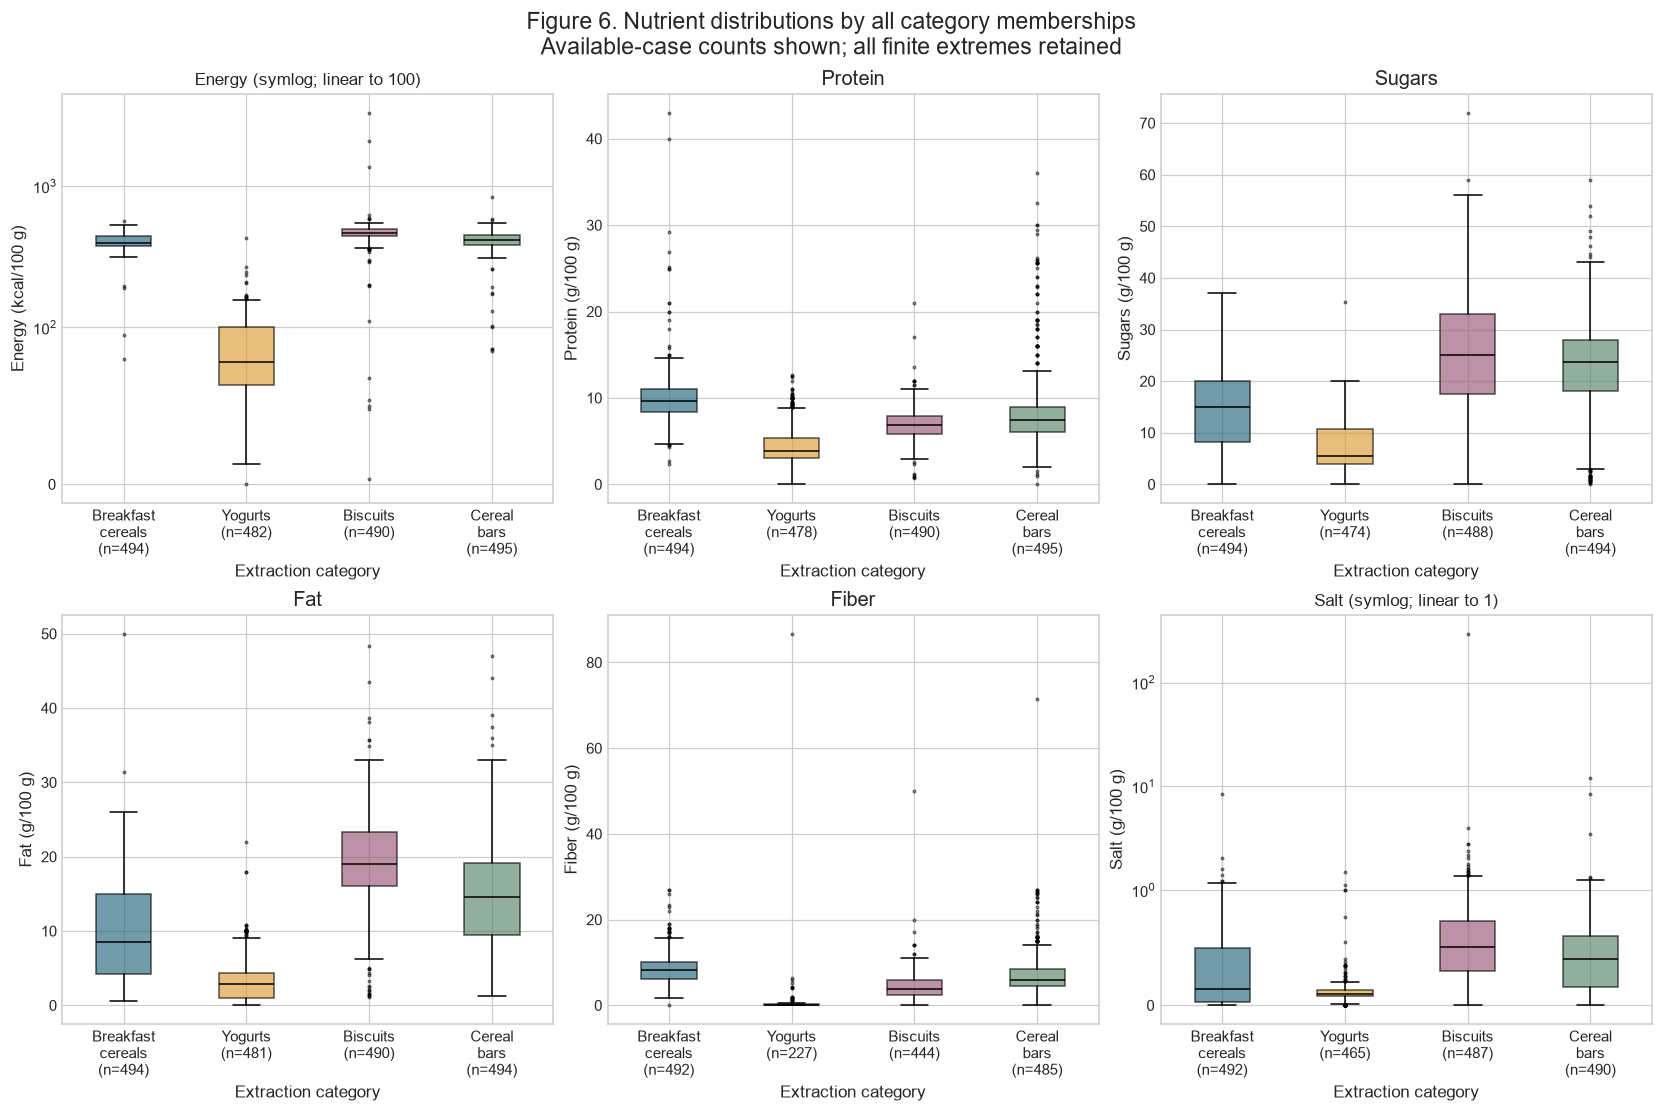

**Interpretation.** Median energy (kcal/100 g) is Breakfast cereals: 397.39; Yogurts: 78.00; Biscuits: 467.00; Cereal bars: 416.67. Median sugars (g/100 g) are Breakfast cereals: 15.00; Yogurts: 5.50; Biscuits: 25.00; Cereal bars: 23.73. Yogurt products in this sample have lower median energy and sugars, but these are per-mass comparisons rather than per-serving comparisons. Energy and salt use a labelled symmetric-log scale to retain zero and extreme values without flattening the central distributions. Boxplot fliers are statistical flags, not verified errors. Fiber is available for only 227 of 500 yogurt memberships, so its available-case median does not summarize all sampled yogurts.

In [13]:
# Figure 6: six panels form one category-distribution figure. No finite outliers are removed.
plotted_nutrients = ["energy_kcal_100g", "protein_g_100g", "sugars_g_100g", "fat_g_100g", "fiber_g_100g", "salt_g_100g"]
fig, axes = plt.subplots(2, 3, figsize=(15, 10), layout="constrained")
for ax, column in zip(axes.flat, plotted_nutrients):
    samples = [nutrient_memberships.loc[nutrient_memberships["membership"].eq(c), column].dropna().to_numpy() for c in CATEGORIES]
    plot = ax.boxplot(samples, patch_artist=True, showfliers=True,
                      tick_labels=[LABELS[c].replace(" ", "\n") + f"\n(n={len(values)})" for c, values in zip(CATEGORIES, samples)],
                      flierprops={"marker": ".", "markersize": 3, "alpha": .6},
                      medianprops={"color": "black"})
    for patch, category in zip(plot["boxes"], CATEGORIES):
        patch.set_facecolor(COLORS[category])
        patch.set_alpha(.65)
    ax.set(title=NUTRIENTS[column].split(" (")[0], ylabel=NUTRIENTS[column], xlabel="Extraction category")
    if column in ["energy_kcal_100g", "salt_g_100g"]:
        threshold = 100 if column == "energy_kcal_100g" else 1
        ax.set_yscale("symlog", linthresh=threshold)
        ax.set_title(ax.get_title() + f" (symlog; linear to {threshold})", fontsize=11)
fig.suptitle("Figure 6. Nutrient distributions by all category memberships\nAvailable-case counts shown; all finite extremes retained", fontsize=15)
plt.show()
plt.close(fig)
display(Markdown(
    "**Interpretation.** Median energy (kcal/100 g) is "
    + "; ".join(f"{LABELS[c]}: {category_medians.loc[c, 'energy_kcal_100g']:.2f}" for c in CATEGORIES)
    + ". Median sugars (g/100 g) are "
    + "; ".join(f"{LABELS[c]}: {category_medians.loc[c, 'sugars_g_100g']:.2f}" for c in CATEGORIES)
    + ". Yogurt products in this sample have lower median energy and sugars, but these are per-mass "
    "comparisons rather than per-serving comparisons. Energy and salt use a labelled symmetric-log scale "
    "to retain zero and extreme values without flattening the central distributions. Boxplot fliers are "
    "statistical flags, not verified errors. "
    f"Fiber is available for only {int(category_available.loc['yogurts', 'fiber_g_100g'])} of "
    f"{int(all_counts['yogurts'])} yogurt memberships, so its available-case median does not summarize all sampled yogurts."
))

## 8. Data-quality screening: invalid, implausible and unusual are different

The rules below are **transparent EDA review rules, not cleaning instructions**:

| Level | Rule | Interpretation |
| --- | --- | --- |
| Invalid representation/domain | Non-numeric, non-finite or negative nutrient values | Invalid for these nonnegative measurements; distinguish from ordinary missingness |
| Implausible on declared basis | Any gram-denominated field >100 g/100 g; energy >1,000 kcal/100 g (or >4,184 kJ/100 g) | Conservative screening; verify original units/basis before deciding an error or correction |
| Internal consistency concern | Sugars > carbohydrates +0.5 g; saturated fat > fat +0.5 g | Components should ordinarily not exceed totals; 0.5 g is an explicit rounding tolerance |
| Internal consistency concern | Protein + carbohydrates + fat >105 g/100 g | Screening with 5 g tolerance; fiber excluded to avoid definition-dependent double counting |
| Cross-unit discrepancy | `abs(kcal - kJ/4.184) > max(20 kcal, 10% of kcal)` | Declared units may be inconsistent; conversion is an EDA diagnostic, not replacement data |
| Statistical flag only | Outside Q1−1.5×IQR or Q3+1.5×IQR **within a category** | Unusual relative to this sample; potentially legitimate, especially for specialized products |

The energy thresholds and tolerances are analyst-selected review criteria, not
regulatory limits. Rounding, source conventions, mixed measurement bases or data
entry errors could contribute. Flags require source review and may overlap.

In [14]:
gram_columns = [column for column in NUTRIENTS if not column.startswith("energy_")]
gram_flags = finite[gram_columns].gt(100)
kcal, kj = finite["energy_kcal_100g"], finite["energy_kj_100g"]
paired_energy = kcal.notna() & kj.notna()
energy_gap = (kcal - kj / 4.184).abs()
energy_tolerance = np.maximum(20, .10 * kcal)
review_flags = pd.DataFrame({
    "invalid_representation": (conversion_failures | nonfinite | negative).any(axis=1),
    "grams_above_100": gram_flags.any(axis=1),
    "energy_above_screening_limit": kcal.gt(1000) | kj.gt(4184),
    "sugars_above_carbohydrates": finite["sugars_g_100g"].gt(finite["carbohydrates_g_100g"] + .5),
    "saturated_fat_above_fat": finite["saturated_fat_g_100g"].gt(finite["fat_g_100g"] + .5),
    "macro_sum_above_105": finite[["protein_g_100g", "carbohydrates_g_100g", "fat_g_100g"]].sum(axis=1, min_count=3).gt(105),
    "kcal_kj_discrepancy": paired_energy & energy_gap.gt(energy_tolerance),
}, index=df.index)
review_summary = review_flags.sum().rename("flagged_products").to_frame()
review_summary["percent_all_products"] = review_summary["flagged_products"] / len(df) * 100
display(review_summary)
print("Unique products flagged by at least one review rule:", int(review_flags.any(axis=1).sum()))
review_table = df.loc[review_flags.any(axis=1), ["barcode", "product_name", "extraction_categories", *NUTRIENTS]].copy()
review_table["review_reasons"] = review_flags.loc[review_table.index].apply(lambda row: "; ".join(row.index[row]), axis=1)
with pd.option_context("display.max_rows", 120):
    display(review_table)

# Trace the most implausible values back to original saved product dictionaries.
gross_mask = review_flags["grams_above_100"] | review_flags["energy_above_screening_limit"]
raw_keys = {"energy_kcal_100g": "energy-kcal_100g", "energy_kj_100g": "energy-kj_100g",
            "carbohydrates_g_100g": "carbohydrates_100g", "salt_g_100g": "salt_100g"}
source_examples = []
for index, row in df.loc[gross_mask].iterrows():
    original = raw_lookup[(row["extraction_id"], row["source_page"], row["source_record_index"]) ]
    assert original["code"] == row["barcode"]
    for column, key in raw_keys.items():
        source_value = original.get("nutriments", {}).get(key)
        source_examples.append({"barcode": row["barcode"], "field": column,
                                "export_value": row[column], "saved_source_value": source_value,
                                "source_page": row["source_page"], "source_record_index": row["source_record_index"]})
display(pd.DataFrame(source_examples))
display(Markdown(
    f"**Observation.** The maximum salt is {finite['salt_g_100g'].max():.3f} g/100 g, carbohydrates "
    f"{finite['carbohydrates_g_100g'].max():.3f} g/100 g, and energy {kcal.max():.3f} kcal/100 g. "
    "The provenance table exposes the saved source values for review; no decimal shift, unit correction "
    "or deletion is inferred from these observations."
))

,flagged_products,percent_all_products
invalid_representation,0,0.000
grams_above_100,2,0.101
energy_above_screening_limit,3,0.151
sugars_above_carbohydrates,5,0.252
saturated_fat_above_fat,2,0.101
macro_sum_above_105,4,0.201
kcal_kj_discrepancy,83,4.177


Unique products flagged by at least one review rule: 91


,barcode,product_name,extraction_categories,energy_kcal_100g,energy_kj_100g,protein_g_100g,carbohydrates_g_100g,sugars_g_100g,fat_g_100g,saturated_fat_g_100g,fiber_g_100g,salt_g_100g,review_reasons
10,8410076610737,Barre de céréales protéinés,breakfast-cereals,195.000,"2,035.000",10.300,11.000,17.100,11.300,7.400,10.700,0.990,sugars_above_carbohydrates; kcal_kj_discrepancy
100,3421557501685,Muesli croustillant chocolat 500 g,breakfast-cereals,437.000,917.000,4.700,33.000,9.600,6.600,2.200,3.900,0.030,kcal_kj_discrepancy
137,4088600247519,Wheat bisk,breakfast-cereals,562.000,134.000,4.500,26.000,1.700,0.800,0.200,3.800,0.100,kcal_kj_discrepancy
167,5070000126548,"GRANOLA LOW SUGAR, NATURALLY",breakfast-cereals,412.000,"1,963.000",13.200,49.700,7.900,17.900,3.700,17.000,0.060,kcal_kj_discrepancy
296,5059319029702,Rice Krispies,breakfast-cereals,338.591,"1,665.667",7.000,86.667,8.000,1.333,0.333,3.000,0.983,kcal_kj_discrepancy
307,3250392415099,Muesli crisp chocolat noir,breakfast-cereals,410.000,"1,960.100",9.300,63.200,17.300,17.200,5.000,11.400,0.270,kcal_kj_discrepancy
310,0884912004710,grape-nuts cereal,breakfast-cereals,344.828,"1,716.000",10.340,79.310,8.620,2.590,0.000,12.070,1.164,kcal_kj_discrepancy
317,3760336830685,Funky Veggie - Les POP,breakfast-cereals,383.000,"1,824.000",7.800,83.000,19.000,1.500,0.800,2.100,0.010,kcal_kj_discrepancy
351,5018357012411,Simply Delicious Muesli,breakfast-cereals,368.000,"1,703.800",9.600,70.500,14.700,7.300,1.100,9.000,0.030,kcal_kj_discrepancy
415,0016000170032,Cheerios,breakfast-cereals,358.974,"1,801.282",12.821,74.359,5.128,6.410,1.282,10.256,1.218,kcal_kj_discrepancy


,barcode,field,export_value,saved_source_value,source_page,source_record_index
0,8410376033267,energy_kcal_100g,"3,305.109","3,305.109",2,19
1,8410376033267,energy_kj_100g,"1,835.000","1,835.000",2,19
2,8410376033267,carbohydrates_g_100g,65.000,65.000,2,19
3,8410376033267,salt_g_100g,0.750,0.750,2,19
4,8901063139329,energy_kcal_100g,492.000,492.000,2,38
5,8901063139329,energy_kj_100g,"2,064.000","2,064.000",2,38
6,8901063139329,carbohydrates_g_100g,73.400,73.400,2,38
7,8901063139329,salt_g_100g,295.000,295.000,2,38
8,5000168036755,energy_kcal_100g,"2,092.857","2,092.857",3,8
9,5000168036755,energy_kj_100g,"2,012.700","2,012.700",3,8


**Observation.** The maximum salt is 295.000 g/100 g, carbohydrates 120.000 g/100 g, and energy 3305.109 kcal/100 g. The provenance table exposes the saved source values for review; no decimal shift, unit correction or deletion is inferred from these observations.

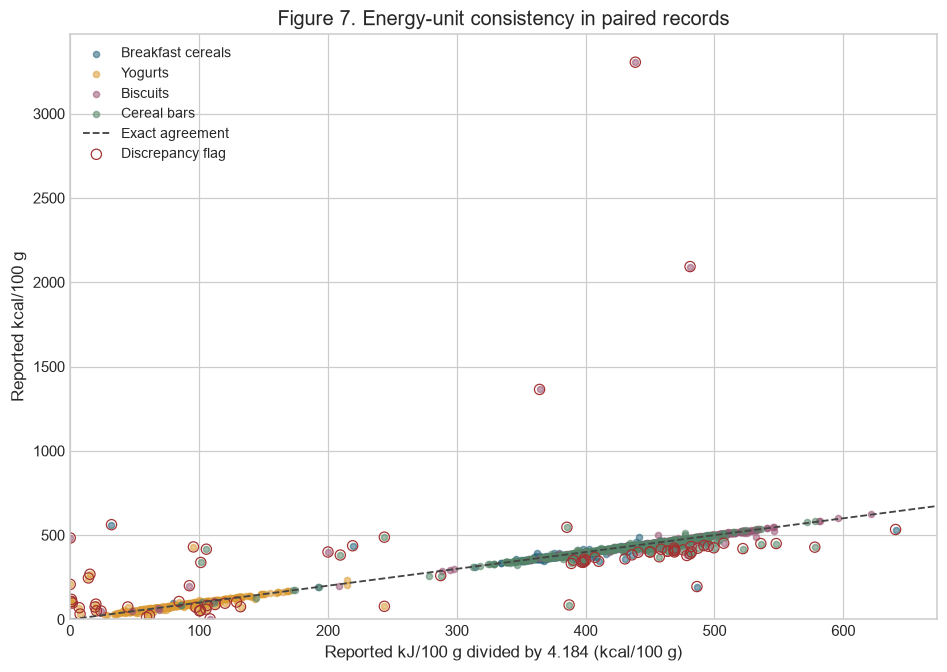

**Interpretation.** 83 of 1,931 paired-energy products (4.30%) exceed the stated discrepancy tolerance. Points above the diagonal report more kcal than their kJ value implies. Each unique product appears once in this diagnostic, colored by retained primary category (unlike the membership-based category comparisons). The full axes retain every paired extreme; no correction is applied.

In [15]:
# Figure 7: exact unit conversion for diagnostics only; no kcal or kJ values overwritten.
fig, ax = plt.subplots(figsize=(8.5, 6), layout="constrained")
for category in CATEGORIES:
    mask = paired_energy & df["extraction_category"].eq(category)
    ax.scatter((kj / 4.184)[mask], kcal[mask], s=16, alpha=.55, color=COLORS[category], label=LABELS[category])
x_limit = (kj[paired_energy] / 4.184).max() * 1.05
y_limit = kcal[paired_energy].max() * 1.05
ax.plot([0, x_limit], [0, x_limit], "--", color="#444444", linewidth=1.2, label="Exact agreement")
flagged = review_flags["kcal_kj_discrepancy"]
ax.scatter((kj / 4.184)[flagged], kcal[flagged], s=45, facecolors="none", edgecolors="#a33131", linewidths=.8, label="Discrepancy flag")
ax.set(xlabel="Reported kJ/100 g divided by 4.184 (kcal/100 g)", ylabel="Reported kcal/100 g",
       title="Figure 7. Energy-unit consistency in paired records", xlim=(0, x_limit), ylim=(0, y_limit))
ax.legend(loc="upper left", fontsize=9)
plt.show()
plt.close(fig)
display(Markdown(
    f"**Interpretation.** {int(flagged.sum())} of {int(paired_energy.sum()):,} paired-energy products "
    f"({flagged.sum() / paired_energy.sum() * 100:.2f}%) exceed the stated discrepancy tolerance. "
    "Points above the diagonal report more kcal than their kJ value implies. Each unique product appears "
    "once in this diagnostic, colored by retained primary category (unlike the membership-based category "
    "comparisons). The full axes retain every paired extreme; no correction is applied."
))

### 8.1 Category-specific statistical outliers

IQR flags are calculated separately by category and nutrient, using all finite
available values. This avoids labeling a yogurt unusual simply because it differs
from a biscuit. A product may be flagged in multiple nutrients/categories; counts
of flagged memberships cannot be summed into a unique-product count.
When IQR is zero, no IQR decision is made. All flagged observations remain present.

In [16]:
iqr_rows, statistical_flags = [], []
for category in CATEGORIES:
    included = memberships.map(lambda values: category in values)
    for column in NUTRIENTS:
        values = finite.loc[included, column].dropna()
        q1, q3 = values.quantile([.25, .75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        unusual = values[(values < lower) | (values > upper)] if iqr > 0 else values.iloc[:0]
        iqr_rows.append({"category": LABELS[category], "nutrient": column, "n": len(values),
                         "q1": q1, "q3": q3, "lower_fence": lower, "upper_fence": upper,
                         "IQR_flags": len(unusual), "evaluated": bool(iqr > 0)})
        for index, value in unusual.items():
            statistical_flags.append({"index": index, "barcode": df.loc[index, "barcode"],
                                      "category": LABELS[category], "nutrient": column, "value": value})
iqr_summary = pd.DataFrame(iqr_rows)
statistical_table = pd.DataFrame(statistical_flags)
display(iqr_summary)
statistical_indices = set(statistical_table["index"]) if not statistical_table.empty else set()
review_indices = set(review_flags.index[review_flags.any(axis=1)])
statistical_only = statistical_indices - review_indices
display(Markdown(
    f"**Interpretation.** {len(statistical_indices)} unique products have at least one category-specific "
    f"IQR flag; {len(statistical_only)} have no accompanying rule-based review flag. "
    "These are potentially legitimate extremes, not an automatic removal list. For example, a high-fiber "
    "or high-protein formulation can differ strongly from its category without being a data-entry error."
))
if statistical_only:
    example_indices = sorted(statistical_only, key=lambda index: finite.loc[index, "protein_g_100g"] if pd.notna(finite.loc[index, "protein_g_100g"]) else -1, reverse=True)[:8]
    display(df.loc[example_indices, ["barcode", "product_name", "extraction_categories", "protein_g_100g", "fiber_g_100g"]])

,category,nutrient,n,q1,q3,lower_fence,upper_fence,IQR_flags,evaluated
0,Breakfast cereals,energy_kcal_100g,494,374.250,441.000,274.125,541.125,5,True
1,Breakfast cereals,energy_kj_100g,492,"1,578.100","1,854.000","1,164.250","2,267.850",6,True
2,Breakfast cereals,protein_g_100g,494,8.400,11.000,4.500,14.900,24,True
3,Breakfast cereals,carbohydrates_g_100g,494,59.500,70.000,43.750,85.750,24,True
4,Breakfast cereals,sugars_g_100g,494,8.225,20.000,-9.438,37.663,0,True
5,Breakfast cereals,fat_g_100g,494,4.225,15.000,-11.938,31.163,2,True
6,Breakfast cereals,saturated_fat_g_100g,493,0.900,3.100,-2.400,6.400,17,True
7,Breakfast cereals,fiber_g_100g,492,6.200,10.000,0.500,15.700,23,True
8,Breakfast cereals,salt_g_100g,492,0.030,0.500,-0.675,1.205,6,True
9,Yogurts,energy_kcal_100g,482,63.000,100.000,7.500,155.500,14,True


**Interpretation.** 500 unique products have at least one category-specific IQR flag; 438 have no accompanying rule-based review flag. These are potentially legitimate extremes, not an automatic removal list. For example, a high-fiber or high-protein formulation can differ strongly from its category without being a data-entry error.

,barcode,product_name,extraction_categories,protein_g_100g,fiber_g_100g
277,3111900350908,Soja et chocolat Protéiné,breakfast-cereals,43.000,9.600
223,3111900350793,Muesli protéiné soja & fruits,breakfast-cereals,40.000,7.200
1801,0722252601414,Chocolate Peanut Butter Protein Bar,cereal-bars,29.412,2.941
417,4056489936183,High Protein Crunchy Musli,breakfast-cereals,29.200,4.800
1828,3608390891382,Barres de protéines croustillantes,cereal-bars,29.000,12.000
183,5060092030977,Lizis high protein granola nuts and seeds,breakfast-cereals,26.900,6.700
1654,4335619073494,NaN,cereal-bars,26.222,3.556
1710,8410076610546,"salted caramel nut, proteine",cereal-bars,26.000,10.750


## 9. Measurement basis and upstream export limitations

This export has no serving-size, package-quantity, original nutrient-unit or
prepared-versus-unprepared fields. A per-serving comparison or a check of serving
unit conversions is therefore unsupported. We retain the declared per-100-g
column labels and do not derive missing serving information from product names.

The existing Phase 1 `numeric()` helper converts missing, non-numeric, negative
and non-finite source inputs to blank analytical cells. The read-only source audit
below separates these cases across the original extracted records; source counts
include repeated category observations and are **not** counts of unique products.
This provenance caveat matters when designing Phase 3 missing-value rules.

In [17]:
measurement_fields = [column for column in df.columns if any(word in column.lower() for word in ["serving", "quantity", "unit", "prepared"])]
print("Serving/unit/preparation fields in analytical CSV:", measurement_fields)
assert not measurement_fields, "Measurement information changed; revisit the limitation"
raw_nutrient_keys = {
    "energy_kcal_100g": "energy-kcal_100g", "energy_kj_100g": "energy-kj_100g",
    "protein_g_100g": "proteins_100g", "carbohydrates_g_100g": "carbohydrates_100g",
    "sugars_g_100g": "sugars_100g", "fat_g_100g": "fat_100g",
    "saturated_fat_g_100g": "saturated-fat_100g", "fiber_g_100g": "fiber_100g", "salt_g_100g": "salt_100g",
}
raw_audit_rows = []
for column, key in raw_nutrient_keys.items():
    counts = {"absent_or_null": 0, "invalid_numeric_or_boolean": 0, "negative": 0, "nonfinite": 0, "finite_nonnegative": 0}
    for record in raw_rows:
        source_nutrients = record["product"].get("nutriments") or {}
        value = source_nutrients.get(key)
        if value is None:
            counts["absent_or_null"] += 1
            continue
        try:
            if isinstance(value, bool):
                raise ValueError("Boolean is not a nutritional measurement")
            number = float(value)
        except (TypeError, ValueError, OverflowError):
            counts["invalid_numeric_or_boolean"] += 1
            continue
        if not np.isfinite(number):
            counts["nonfinite"] += 1
        elif number < 0:
            counts["negative"] += 1
        else:
            counts["finite_nonnegative"] += 1
    assert sum(counts.values()) == len(raw_rows)
    raw_audit_rows.append({"field": column, **counts})
raw_audit = pd.DataFrame(raw_audit_rows).set_index("field")
display(raw_audit)
display(Markdown(
    f"**Source audit.** Across the {len(raw_rows):,} extracted records and nine nutrient fields, "
    f"{int(raw_audit['negative'].sum())} negative, {int(raw_audit['nonfinite'].sum())} non-finite and "
    f"{int(raw_audit['invalid_numeric_or_boolean'].sum())} invalid numeric/Boolean cells were found. "
    "Absent/null source cells are listed separately; missing values should not be assigned a cause solely from the combined CSV."
))

Serving/unit/preparation fields in analytical CSV: []


,absent_or_null,invalid_numeric_or_boolean,negative,nonfinite,finite_nonnegative
field,,,,,
energy_kcal_100g,39,0,0,0,1961
energy_kj_100g,55,0,0,0,1945
protein_g_100g,43,0,0,0,1957
carbohydrates_g_100g,44,0,0,0,1956
sugars_g_100g,50,0,0,0,1950
fat_g_100g,41,0,0,0,1959
saturated_fat_g_100g,54,0,0,0,1946
fiber_g_100g,352,0,0,0,1648
salt_g_100g,66,0,0,0,1934


**Source audit.** Across the 2,000 extracted records and nine nutrient fields, 0 negative, 0 non-finite and 0 invalid numeric/Boolean cells were found. Absent/null source cells are listed separately; missing values should not be assigned a cause solely from the combined CSV.

## 10. EDA conclusions and proposed Phase 3 considerations

The findings below are computed from the current run. Proposed actions are
questions/rules to evaluate in Phase 3; **none is implemented here**.

In [18]:
summary = [
    ("Identity and membership", f"{len(df):,} unique barcode rows; {len(overlap)} overlapping products; all saved memberships verified.",
     "Keep barcodes as text and preserve many-to-many category membership; do not deduplicate on names."),
    ("Missing nutrition", f"Fiber missing for {int(missing.loc['fiber_g_100g','missing_count'])} ({missing.loc['fiber_g_100g','missing_pct']:.2f}%); salt missing for {int(missing.loc['salt_g_100g','missing_count'])} ({missing.loc['salt_g_100g','missing_pct']:.2f}%).",
     "Choose field- and category-specific missingness rules, retaining missing-versus-zero distinctions; avoid blanket imputation."),
    ("Names and brands", f"{int(missing.loc['product_name','missing_count'])} missing names; {int(missing.loc['brands','missing_count'])} missing brands.",
     "Review text whitespace/case variants and multi-brand strings before defining a normalization rule; retain original text."),
    ("Implausible measurements", f"{int(review_flags['grams_above_100'].sum())} products exceed 100 g/100 g; {int(review_flags['energy_above_screening_limit'].sum())} exceed the energy screen.",
     "Review original labels and saved source values before correction or quarantine. Do not guess decimal shifts or measurement units."),
    ("Internal consistency", f"{int(review_flags['sugars_above_carbohydrates'].sum())} sugar/carbohydrate, {int(review_flags['saturated_fat_above_fat'].sum())} saturated/total-fat and {int(review_flags['macro_sum_above_105'].sum())} macro-sum flags.",
     "Define source-review and rounding-tolerance policies; preserve an audit reason for each decision."),
    ("Energy units", f"{int(review_flags['kcal_kj_discrepancy'].sum())}/{int(paired_energy.sum())} paired values disagree beyond the explicit tolerance.",
     "Establish a documented source/unit preference only after source review; do not overwrite one energy measure automatically."),
    ("Statistical extremes", f"{len(statistical_indices)} products have IQR flags; {len(statistical_only)} have no rule-based review flag.",
     "Assess legitimate specialized formulations; avoid automatic winsorization or deletion based only on IQR."),
    ("Classification coverage", f"{int(grade_counts['Missing'])} missing Nutri-Score; {int(nova_counts['Missing'])} missing NOVA.",
     "Keep unclassified products explicit and document denominators; do not infer classifications."),
    ("Extraction provenance", f"{int(missing.loc['extracted_at_utc','missing_count'])} missing original extraction timestamps, all legacy imports.",
     "Keep unknown historical timestamps unknown; do not substitute import times."),
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(summary, columns=["Issue", "Observed evidence", "Phase 3 consideration"]))

,Issue,Observed evidence,Phase 3 consideration
0,Identity and membership,"1,987 unique barcode rows; 13 overlapping products; all saved memberships verified.",Keep barcodes as text and preserve many-to-many category membership; do not deduplicate on names.
1,Missing nutrition,Fiber missing for 351 (17.66%); salt missing for 66 (3.32%).,"Choose field- and category-specific missingness rules, retaining missing-versus-zero distinctions; avoid blanket imputation."
2,Names and brands,40 missing names; 32 missing brands.,Review text whitespace/case variants and multi-brand strings before defining a normalization rule; retain original text.
3,Implausible measurements,2 products exceed 100 g/100 g; 3 exceed the energy screen.,Review original labels and saved source values before correction or quarantine. Do not guess decimal shifts or measurement units.
4,Internal consistency,"5 sugar/carbohydrate, 2 saturated/total-fat and 4 macro-sum flags.",Define source-review and rounding-tolerance policies; preserve an audit reason for each decision.
5,Energy units,83/1931 paired values disagree beyond the explicit tolerance.,Establish a documented source/unit preference only after source review; do not overwrite one energy measure automatically.
6,Statistical extremes,500 products have IQR flags; 438 have no rule-based review flag.,Assess legitimate specialized formulations; avoid automatic winsorization or deletion based only on IQR.
7,Classification coverage,116 missing Nutri-Score; 130 missing NOVA.,Keep unclassified products explicit and document denominators; do not infer classifications.
8,Extraction provenance,"100 missing original extraction timestamps, all legacy imports.",Keep unknown historical timestamps unknown; do not substitute import times.


### Limitations and scope boundary

- **Nonrandom sampling:** four category queries targeted 500 records each, with
  API-default ordering. This convenience sample does not represent all Open Food
  Facts products, all countries, market shares or consumer purchases.
- **Missingness:** available-case comparisons use different denominators for
  different nutrients; missingness may be systematic. The exploratory summaries
  do not establish that data are missing at random.
- **Classification coverage:** Nutri-Score and NOVA are incomplete, source-provided
  fields and are not independently validated or recalculated in this notebook.
- **Overlap and retained versions:** category groups share products. The combiner
  kept the first category's values and combined memberships, so later source
  versions are not independent observations in these comparisons.
- **Measurement uncertainty:** serving information and original units/basis are
  absent from the combined export. The per-100-g interpretation follows column
  labels; labels alone cannot resolve an incorrect source unit or preparation basis.
- **Outlier interpretation:** IQR and plausibility rules prioritize review; they do
  not prove an error. Extreme values affect means and plot scales. No records are removed.
- **Time and provenance:** extraction snapshots can differ in time, and legacy
  extraction timestamps are unknown. These data do not support time trends.

Sources are the combined CSV/adjacent metadata and saved Phase 1 checkpoints and
page responses, verified above. The existing `src/download_dataset.py` defines
export and combination semantics. No external or live data were added.

**Stop point:** Phase 2 is complete after verification below. Cleaning,
transformation, database design/loading and SQL reporting are outside this notebook.

In [19]:
pd.testing.assert_frame_equal(df, original_frame)
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == csv_hash_before
assert len(df) == metadata["unique_products"]
assert len(membership_view) == metadata["raw_records"]
assert set(df["barcode"]) == set(raw_memberships)
print("Verification passed: original DataFrame and CSV unchanged; counts and memberships reconcile.")
print("Seven figures rendered. No cleaned dataset was written and no API request was made.")

Verification passed: original DataFrame and CSV unchanged; counts and memberships reconcile.
Seven figures rendered. No cleaned dataset was written and no API request was made.
